# Infinite Horizon Problem

(If GitHub truncates the output, you can view the full rendering on nbviewer: click [here](https://nbviewer.org/github/Kanato-Nakakuni/ComputationalMacro/blob/main/Lecture%20notes/Lec07_InfiniteHorizon.ipynb).)  

---
- So far, we have learned how to solve the **finite-horizon** problem.

- Today, we will learn how to solve the **infinite-horizon** problem.  
  - Broad applications in macroeconomics, not limited to household problems.

- How to solve it:  
  - We cannot use backward induction because there is no terminal period.  
  - The key method: **Value Function Iteration (VFI)**.

---

### Setup  

- Households make consumption-saving decisions over the infinite horizon, taking interest rates $r_t$ and wage rates $w_t$ given.  

- They supply one unit of labor exogenously and earn labor income $w_t$.  

- The household problem reads as follows:  

\begin{align*}
    & \max_{\{c_t,a_{t+1}\}_{t=0}^\infty} \sum_{t=0}^{\infty} \beta^t u(c_t)\\
    \text{s.t.} & \\
    & c_t = (1+r_{t})a_{t} - a_{t+1} + w_t \\
    & a_0\ge 0: \text{given}, a_{t+1} \ge 0~~~\forall t
\end{align*}

---

## Recursive formulation
Let $V_t(a)$ be the lifetime utility from the viewpoint of time $t$ with asset level $a$, which is defined as:

$$
V_t(a_t) = \max_{a_{t+1}} u((1+r_t)a_t - a_{t+1} + w_t) + \beta V_{t+1}(a_{t+1})
$$

Here, think about the stationary economy in which these prices are constant over time, meaning that we do not need information on time $t$:

$$
V(a) = \max_{a'} u((1+r)a - a' + w) + \beta V(a'),
$$
where $a'$ is the next period's asset position. The solution is the policy function for saving that returns the optimal asset position for next period:

$$
g(a) = \argmax_{a'}  u((1+r)a - a' + w) + \beta V(a')
$$

We want to find solutions for the value function $V(\cdot)$ and the corresponding policy function $g(\cdot)$.  

---

### Solution methods:

### Value Function Iteration (VFI)

1. Choose an initial guess $V^k(a)$ on the asset grid $\mathcal{A}$ and set $k=0$.
2. Given $V^k(a)$, compute the updated value function:
   $$
   V^{k+1}(a) = \max_{a'}
   \left\{u((1+r)a+w-a')+\beta V^k(a')\right\}.
   $$
3. Check whether
   $$
   \max_{a\in\mathcal{A}}\left|V^{k+1}(a)-V^k(a)\right|<\varepsilon,
   $$
   where $\varepsilon>0$ is the convergence tolerance. If satisfied, stop. Otherwise, set $k \leftarrow k+1$ and return to Step 2.

### Policy Function Iteration (PFI)

1. Choose an initial feasible policy $g^k(a)$ on the asset grid $\mathcal{A}$ and set $k=0$.
2. **Policy evaluation:** Given $g^k(a)$, solve for its value function $V^k(a)$:
   $$
   V^k(a)=u((1+r)a+w-g^k(a))+\beta V^k(g^k(a)).
   $$
3. **Policy improvement:** Compute the updated policy:
   $$
   g^{k+1}(a)\in\arg\max_{a'}
   \left\{u((1+r)a+w-a')+\beta V^k(a')\right\}.
   $$
4. Check whether
   $$
   \max_{a\in\mathcal{A}}\left|g^{k+1}(a)-g^k(a)\right|<\varepsilon,
   $$
   where $\varepsilon>0$ is the convergence tolerance. If satisfied, stop. Otherwise, set $k \leftarrow k+1$ and return to Step 2.

In [47]:
### VALUE FUNCTION ITERATION

# parameters
β = 0.98
r = 0.05
w = 1.0

penalty = -1.e+8

# discretization
amin = 1.e-5
amax = 10.0
na   = 1000
agrid = collect(LinRange(amin,amax,na))

# Value function and policy function
Va = zeros(na)
ga = zeros(na)

# convergence criterion
ε = 1.e-7
dif = 1.0
iter = 1
maxiter = 2000
Va_it = zeros(na,maxiter) # (optional) for plot

# outer loop: guess and update value function
Va_guessed = copy(Va)
Va_implied = copy(Va)

while (dif>ε)

    # compute optimal saving choices and implied value functions
    acc_start=1
    for ac in 1:na
        v0=penalty
        for acc in acc_start:na
            c = (1+r)*agrid[ac]-agrid[acc]+w
            if (c>0)
                v_new=log(c)+β*Va_guessed[acc]
            else
                v_new=penalty
            end

            if (v_new>v0)
                v0=v_new
                acc_start=acc
            else
                break
            end
        end
        Va_implied[ac]=v0
        ga[ac]=agrid[acc_start]
    end

    dif = maximum(abs.(Va_guessed.-Va_implied))

    Va_it[:,iter] .= Va_guessed[:] # for plot
    if (dif<ε)
        Va .= Va_guessed
    else
        # update
        # Va_guessed .= (Va_guessed.+Va_implied)./2.0
        Va_guessed .= Va_implied
        iter+=1
        if (iter>maxiter)
            println("failure: iter_v>maxiter_v")
            break
        end
    end

end

In [48]:
@show iter
@show dif

iter = 741
dif = 9.886956675586589e-8


9.886956675586589e-8

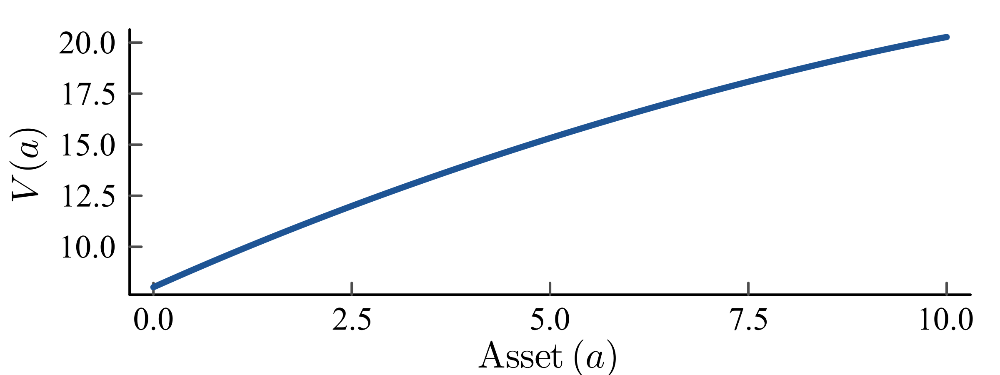

In [49]:
# plot value function and policy function
using Plots
using LaTeXStrings

blue = RGB(0.12, 0.33, 0.58)

# Value function
pV = plot(agrid, Va;
    xlabel=L"\mathrm{Asset}\ (a)",
    ylabel=L"V(a)",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes
)

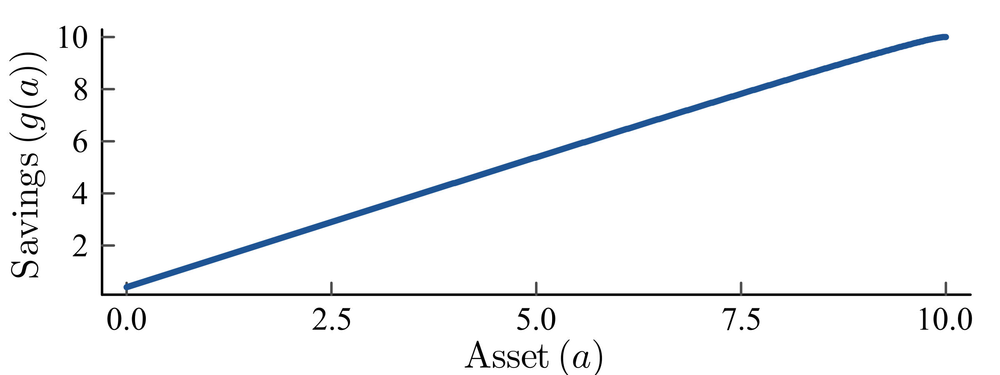

In [50]:
# plot policy function
using Plots
using LaTeXStrings

blue = RGB(0.12, 0.33, 0.58)

# Policy function
pG = plot(agrid, ga;
    xlabel=L"\mathrm{Asset}\ (a)",
    ylabel=L"\mathrm{Savings}\ (g(a))",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes
)

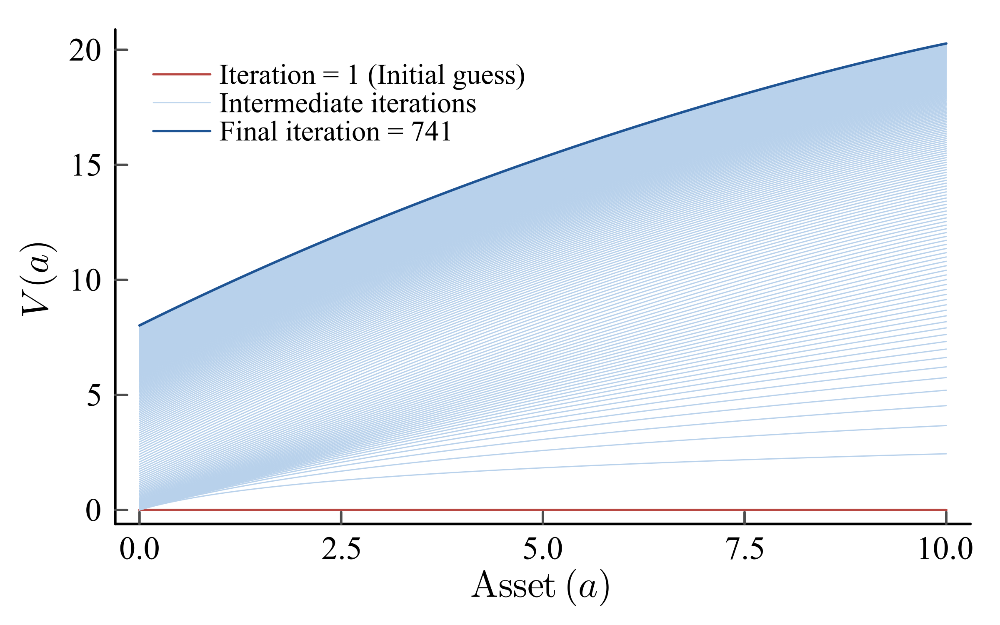

In [51]:
using Plots
using LaTeXStrings

red  = RGB(0.72, 0.28, 0.26)
blue = RGB(0.12, 0.33, 0.58)
gray = RGB(0.65, 0.65, 0.65)
light_blue = RGB(0.72, 0.82, 0.92)

intermediate_ts = 2:(iter - 1)

plt = plot(
    xlabel=L"\mathrm{Asset}\ (a)",
    ylabel=L"V(a)",
    legend=:topleft,
    dpi=600,
    size=(400, 250),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=7,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    background_color_legend=:transparent,
    foreground_color_legend=:transparent,
    grid=false,
    framestyle=:axes
)

# Initial iteration
plot!(plt, agrid, Va_it[:, 1];
    label="Iteration = 1 (Initial guess)",
    lw=1.0,
    lc=red
)

# Intermediate iterations: one shared legend entry
for (i, t) in enumerate(intermediate_ts)
    plot!(plt, agrid, Va_it[:, t];
        label=i == 1 ? "Intermediate iterations" : "",
        lw=0.5,
        lc=light_blue
    )
end

# Final iteration
plot!(plt, agrid, Va_it[:, iter];
    label="Final iteration = $(iter)",
    lw=1.0,
    lc=blue
)

display(plt)
# savefig(plt, joinpath("figures", "lec10-value-function-iteration.svg")) # save

In [39]:
### POLICY FUNCTION ITERATION

# parameters
β = 0.98
r = 0.05
w = 1.0

penalty = -1.e+8

# discretization
amin = 1.e-5
amax = 10.0
na   = 1000
agrid = collect(LinRange(amin,amax,na))

# Value function and policy function
Va = zeros(na) 
ga = fill(amin,na)

# convergence criterion
tol = 1.e-7
dif = 1.0
iter = 1
maxiter = 1000

# outer loop: guess and update policy function
ga_guessed = copy(ga)
ga_implied = copy(ga)

ga_guessed_arg = ones(Int,na)
ga_implied_arg = ones(Int,na)
# initial guess g(a)=a
for ac in 1:na
    ga_guessed_arg[ac] = ac
end

Va_guessed = copy(Va)
Va_implied = copy(Va)

while (dif>tol)

    # compute value function consistent with the guessed policy function
    dif_v = 1.0 # difference of guessed and implied value functions
    iter_v=1
    maxiter_v = 10000
    while (dif_v>tol)
        for ac in 1:na
            # compute value function
            arg_a = ga_guessed_arg[ac]
            c = (1.0+r)*agrid[ac] - agrid[arg_a] + w
            if (c>0)
                Va_implied[ac] = log(c) + β*Va_guessed[arg_a]
            else
                Va_implied[ac] = penalty
            end
            
        end

        dif_v = maximum(abs.(Va_guessed.-Va_implied))
        if (dif_v>tol)
            #update
            Va_guessed .= (Va_guessed.+Va_implied)./2.0
            iter_v+=1
        else
            Va .= Va_guessed
        end

        if (iter_v>maxiter_v)
            println("failure: iter_v>maxiter_v")
        end

    end
    
    # compute implied policy function
    acc_start=1
    dif=0.0
    # compute optimal saving choices and implied value functions
    for ac in 1:na
        v0=penalty
        for acc in acc_start:na
            c = (1+r)*agrid[ac]-agrid[acc]+w
            if (c>0)
                v_new=log(c)+β*Va[acc]
            else
                v_new=penalty
            end

            if (v_new>v0)
                v0=v_new
                acc_start=acc
            else
                break
            end
        end

        ga_implied_arg[ac] = acc_start
        ga_implied[ac] = agrid[acc_start]
        acc_guess = ga_guessed_arg[ac]

        if (acc_guess ≠ acc_start)
            # update
            dif = abs(acc_guess-acc_start) # if acc_guess==acc_start for any ac, dif=0.
            if (dif==1)
                ga_guessed_arg[ac] = acc_start
            else
                mid_point = (acc_guess+acc_start)/2.0
                ga_guessed_arg[ac] = round(Int, mid_point) 
            end
        end

    end

    if (dif<tol)
        ga .= ga_implied
    else
        iter+=1
    end
    
    if (iter>maxiter)
        println("failure: iter>maxiter")
        break
    end
end
@show dif;
@show iter;

dif = 0.0
iter = 24


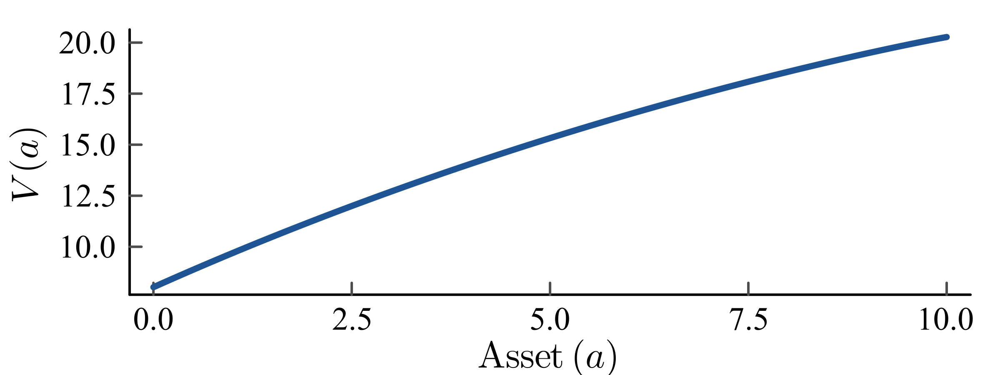

In [40]:
using Plots
using LaTeXStrings

blue = RGB(0.12, 0.33, 0.58)

pV = plot(agrid, Va;
    xlabel=L"\mathrm{Asset}\ (a)",
    ylabel=L"V(a)",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes
)

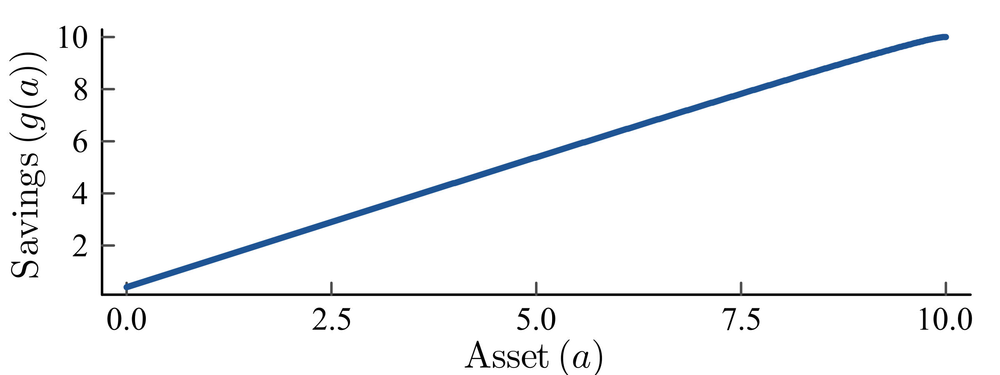

In [41]:
# plot policy function
using Plots
using LaTeXStrings

blue = RGB(0.12, 0.33, 0.58)

pG = plot(agrid, ga;
    xlabel=L"\mathrm{Asset}\ (a)",
    ylabel=L"\mathrm{Savings}\ (g(a))",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes
)

### An Application: Inter Vivos Transfers with Altruism

Consider a three-period model with consumption, saving, and **inter vivos transfers (IVT)**—transfers from parents to children during the parents' lifetime. A common example is financial support for children's college education. A similar computational approach can also be applied to models with bequests. These intergenerational transfers have been shown to be important in explaining the wealth inequality and intergenerational mobility.

Households live for three periods: young age, middle age, and old age. They receive exogenous labor income $w$ when young and middle-aged, and no labor income when old. Savings earn a net interest rate $r$.

At the beginning of middle age, households choose how much to transfer to their young children, denoted by $a_{\mathrm{IVT}}$. Parents value their children's lifetime utility, with altruism parameter $\delta$.

The household's problem is:

\begin{align*}
V_y(a) = \max_{c_y,c_m,c_o,a_y,a_m,a_{\mathrm{IVT}}}
& \quad \ln(c_y) + \beta \ln(c_m) + \beta^2 \ln(c_o)
+ \delta V_y(a_{\mathrm{IVT}}) \\
\text{s.t.}
& \quad c_y + a_y = a + w, \\
& \quad c_m + a_m + a_{\mathrm{IVT}} = (1+r)a_y + w, \\
& \quad c_o = (1+r)a_m, \\
& \quad c_y,c_m,c_o > 0,\qquad a_y,a_m,a_{\mathrm{IVT}} \geq 0.
\end{align*}

Here, $\beta$ is the discount factor, and $V_y(a)$ denotes lifetime utility for a young household with initial assets $a$. The term $\delta V_y(a_{\mathrm{IVT}})$ captures the value parents place on their children's welfare: the transfer becomes the children's initial assets.

**Why is backward induction alone insufficient?**

In a standard finite-horizon model, we solve the household's problem backward from the final period. Here, however, the middle-aged household's transfer decision depends on the children's value function $V_y$. This is the same function we are trying to compute.

**Solution: combine backward induction with value function iteration.**

Treat $V_y$ as an unknown function and find it numerically:

1. Discretize the asset space $\mathcal{A}$.
2. Choose an initial guess $V_y^{(0)}(a)$ on this grid.
3. Given $V_y^{(k)}$ as the children's value function, solve the household's problem by backward induction to obtain an updated value function $V_y^{(k+1)}$.
4. Check whether
   $$
   \max_{a\in\mathcal{A}}
   \left|V_y^{(k+1)}(a)-V_y^{(k)}(a)\right| < \varepsilon.
   $$
   If not, update the guess and repeat Step 3.

At convergence, the value function used to evaluate the children's welfare is consistent with the value function generated by optimal household decisions.

In [147]:
# Solve a three-period model with IVT
function solve_IVT(β, δ, r, w, na)

    # β: time discount
    # δ: altruistic discount
    # r,w: interest rate, wage rate
    # na: # of grid points
    
    # Step 1. Discretization
    mina = 1.e-5
    maxa = 100.0
    grida = collect(LinRange(mina, maxa, na))

    R = 1 + r

    # Step 2. Initial guess (value functions)
    V_y_guess = zeros(na)
    V_y_implied = zeros(na)
    V_m = zeros(na)

    # policy function
    a_y = zeros(na)
    a_m = zeros(na)
    a_IVT = zeros(na)

    # Old-age utility
    V_o(a) = β^2 * log(R * a) # function

    # Convergence criteria
    ε = 1.e-8
    d = 1.0
    iter=1
    maxiter=1000

    # for plot
    V_y_iter = zeros(na,maxiter)
    a_IVT_iter = zeros(na,maxiter)

    while (d > ε)

        V_y_iter[:,iter] = V_y_guess;

        # Step 3. Backward induction: middle age
        for ac in 1:na # today's asset position
            resources = R * grida[ac] + w
            best = -Inf # for speed up

            for at in 1:na # IVT
                remaining = resources - grida[at]
                remaining <= 0 && break

                # Given IVT: a_m = β*c_m
                c_m = remaining / (1 + β)
                saving = β * c_m

                value = β * log(c_m) + V_o(saving) +
                        δ * V_y_guess[at]

                if value > best
                    best = value
                    a_m[ac] = saving
                    a_IVT[ac] = grida[at]
                end
            end
            a_IVT_iter[:,iter]=a_IVT
            V_m[ac] = best
        end

        # Young age
        for ac in 1:na # Today's asset position
            best = -Inf

            for acc in 1:na # saving
                c_y = grida[ac] + w - grida[acc]
                c_y <= 0 && break

                # V_m already includes discounting β
                value = log(c_y) + V_m[acc]

                if value > best
                    best = value
                    a_y[ac] = grida[acc]
                end
            end
            V_y_implied[ac] = best
        end

        # Step 4. Check convergence and update
        d = maximum(abs.(V_y_implied .- V_y_guess))

        
        if (iter>maxiter)
            break
        else
            if (d>ε)
                iter+=1
            end
        end

        V_y_guess .= V_y_implied
    end

    @show iter
    @show d

    return a_IVT, a_IVT_iter, V_y_iter, iter, grida

end

solve_IVT (generic function with 1 method)

In [155]:
β = 0.8; δ = 0.3; r = 1.2; w = 1.0; na = 1000;
a_IVT, a_IVT_iter, V_y_iter, iter, grida = solve_IVT(β, δ, r, w, na);

iter = 15
d = 4.132012065838353e-9


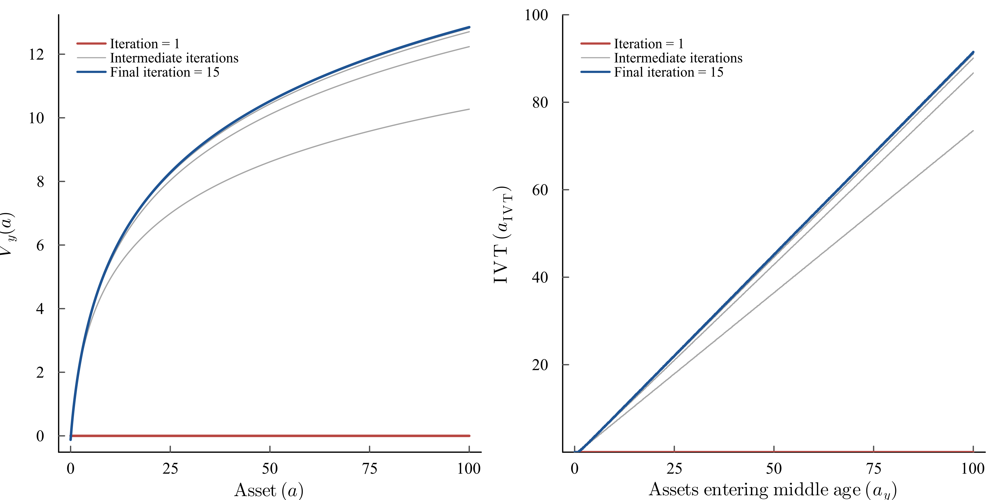

In [156]:
using Plots
using LaTeXStrings

red  = RGB(0.72, 0.28, 0.26)
blue = RGB(0.12, 0.33, 0.58)
gray = RGB(0.65, 0.65, 0.65)

# Shared styling
style = (
    legend=:topleft,
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=7,
    background_color=:white,
    foreground_color_axis=:gray30,
    background_color_legend=:transparent,
    foreground_color_legend=:transparent,
    grid=false,
    framestyle=:axes
)

pV = plot(;
    style...,
    xlabel=L"\mathrm{Asset}\ (a)",
    ylabel=L"V_y(a)"
)

pIVT = plot(;
    style...,
    xlabel=L"\mathrm{Assets\ entering\ middle\ age}\ (a_y)",
    ylabel=L"\mathrm{IVT}\ (a_{\mathrm{IVT}})"
)

# Add iteration curves to both panels
for (p, values) in ((pV, V_y_iter), (pIVT, a_IVT_iter))
    plot!(p, grida, values[:, 1];
        label="Iteration = 1",
        lw=2.0,
        lc=red
    )

    for x in 2:(iter - 1)
        plot!(p, grida, values[:, x];
            label=x == 2 ? "Intermediate iterations" : "",
            lw=1.0,
            lc=gray
        )
    end

    plot!(p, grida, values[:, iter];
        label="Final iteration = $(iter)",
        lw=2.0,
        lc=blue
    )
end

plot!(pIVT; ylims=(minimum(grida), maximum(grida)))

# Combine side by side
plt = plot(pV, pIVT;
    layout=(1, 2),
    size=(800, 400),
    dpi=600
)

display(plt)